# 01 — Exploring Image Data (EDA)

**Seminar Nhận diện mẫu · Chapter 4 — Exploring Image Data**  
**Notebook:** `notebooks/01_EDA.ipynb` · **Phạm vi:** Trực quan hóa và phân tích một ảnh mẫu

**Mục tiêu:** Hiểu cách ảnh được biểu diễn bằng các giá trị số, quan sát RGB/grayscale, tách ba kênh màu và dùng histogram để nhận xét về phân bố pixel.

| Phần | Nội dung | Kết quả |
|---|---|---|
| 01 | Introduction to Image EDA | Mục đích và giới hạn |
| 02 | Load & Visualize RGB Image | Thí nghiệm 1 |
| 03 | Grayscale Conversion | Thí nghiệm 2 |
| 04 | RGB Channel Visualization | Thí nghiệm 3 |
| 05 | Image Histogram Analysis | Thí nghiệm 4–5 |
| 06 | EDA Insights & Conclusions | Nhận xét và kết luận |

<br>

> **Nguồn:** Vijaya Kumar Suda (2024), *Data Labeling in Machine Learning with Python*, Chapter 4, trang PDF 2–13, các Hình 4.1–4.5. Tham khảo code tác giả: [PacktPublishing/Ch04](https://github.com/PacktPublishing/Data-Labeling-in-Machine-Learning-with-Python/tree/main/code/Ch04).  
> Nội dung notebook này **không bao gồm** segmentation/HOG, resize/normalization/augmentation.

## 01. Introduction to Image EDA

**EDA (Exploratory Data Analysis)** là quá trình tìm hiểu dữ liệu trước khi đưa vào mô hình.

Với ảnh, EDA thường trả lời:
- Kích thước ảnh, số kênh màu và kiểu dữ liệu là gì?
- Giá trị màu và độ sáng phân bố ra sao?
- Có dấu hiệu bất thường cần kiểm tra không?
- Nên giữ RGB hay chuyển grayscale cho bài toán cụ thể?

**Giới hạn của notebook:** Chúng ta chỉ khảo sát **một ảnh hoa hồng**. Không thể dùng một ảnh để kết luận về mất cân bằng lớp, ảnh ngoại lệ hay chất lượng của *toàn bộ tập dữ liệu*.

**Quy trình:** Đọc ảnh → Kiểm tra cấu trúc → Trực quan hóa → Phân tích histogram → Rút ra nhận xét.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Notebook có thể được chạy từ thư mục gốc hoặc từ notebooks/.
# Tìm gốc repo theo vị trí ảnh mẫu đã được chia sẻ.
project_root = next(
    (folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (folder / 'images' / 'roseflower.jpeg').is_file()
     and (folder / 'notebooks').is_dir()),
    None
)
if project_root is None:
    raise FileNotFoundError(
        'Không tìm thấy gốc dự án. Hãy mở toàn bộ thư mục PR_Seminar_Chapter04 '
        'bằng VS Code và giữ ảnh images/roseflower.jpeg.'
    )

image_path = project_root / 'images' / 'roseflower.jpeg'
OUTPUT_DIR = project_root / 'outputs' / 'thien'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 115
print('Project root:', project_root)
print('Ảnh đang sử dụng:', image_path)
print('Kết quả được lưu tại:', OUTPUT_DIR)


Project root: /home/thien408/Projects/2026-2027/PR_seminar_bakhi
Ảnh đang sử dụng: /home/thien408/Projects/2026-2027/PR_seminar_bakhi/images/roseflower.jpeg
Kết quả được lưu tại: /home/thien408/Projects/2026-2027/PR_seminar_bakhi/outputs/thien


## 02. Load & Visualize RGB Image — Thí nghiệm 1

**Mục đích:** Đọc ảnh màu, kiểm tra cấu trúc và hiển thị ảnh.

- `Image.open()` đọc ảnh bằng Pillow (PIL).
- `.convert('RGB')` bảo đảm ảnh có ba kênh R, G, B.
- `np.asarray()` chuyển ảnh thành mảng số để phân tích từng pixel.
- `plt.imshow()` hiển thị ảnh.

Một ảnh RGB có cấu trúc **`(height, width, 3)`**. Với ảnh RGB kiểu `uint8`, mỗi kênh có giá trị từ **0 đến 255**.

*Nguồn đối chiếu: Chapter 4, trang PDF 6–7, Hình 4.1.*

Kích thước (rộng × cao): 270 × 270 pixel
Shape của mảng: (270, 270, 3) (height, width, channels)
Kiểu dữ liệu: uint8
Giá trị pixel đầu tiên [R,G,B]: [228, 223, 204]


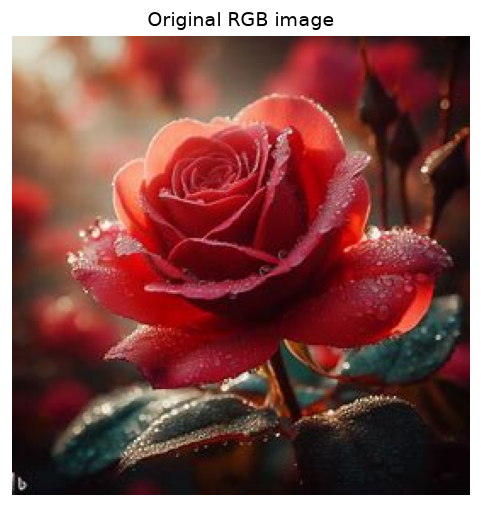

In [2]:
img = Image.open(image_path).convert('RGB')
img_array = np.asarray(img)
height, width, channels = img_array.shape

assert channels == 3 and img_array.dtype == np.uint8
print(f'Kích thước (rộng × cao): {width} × {height} pixel')
print(f'Shape của mảng: {img_array.shape} (height, width, channels)')
print(f'Kiểu dữ liệu: {img_array.dtype}')
print(f'Giá trị pixel đầu tiên [R,G,B]: {img_array[0, 0].tolist()}')

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.imshow(img_array)
ax.set_title('Original RGB image')
ax.axis('off')
plt.tight_layout()
plt.show()

**Quan sát cần rút ra:** Hình ảnh màu chính là kết quả kết hợp ba ma trận giá trị R, G, B. Cùng một pixel được mô tả bằng **ba số**, không phải một màu “có sẵn” trong bộ nhớ máy tính.

## 03. Grayscale Conversion — Thí nghiệm 2

**Mục đích:** Chuyển ảnh RGB sang ảnh mức xám và so sánh trực quan.

- `img.convert('L')` **thực sự chuyển dữ liệu** sang ảnh mức xám 8-bit.
- `cmap='gray'` chỉ là **cách hiển thị** các giá trị số dưới dạng đen–trắng trong Matplotlib.
- Giá trị `0` tương ứng đen, `255` tương ứng trắng (với ảnh mức xám 8-bit).

**Đánh đổi:** Grayscale giữ thông tin sáng/tối nhưng mất thông tin màu. Tính hữu ích phụ thuộc bài toán.

*Nguồn đối chiếu: Chapter 4, trang PDF 8–9, Hình 4.2.*

RGB shape: (270, 270, 3)
Grayscale shape: (270, 270)


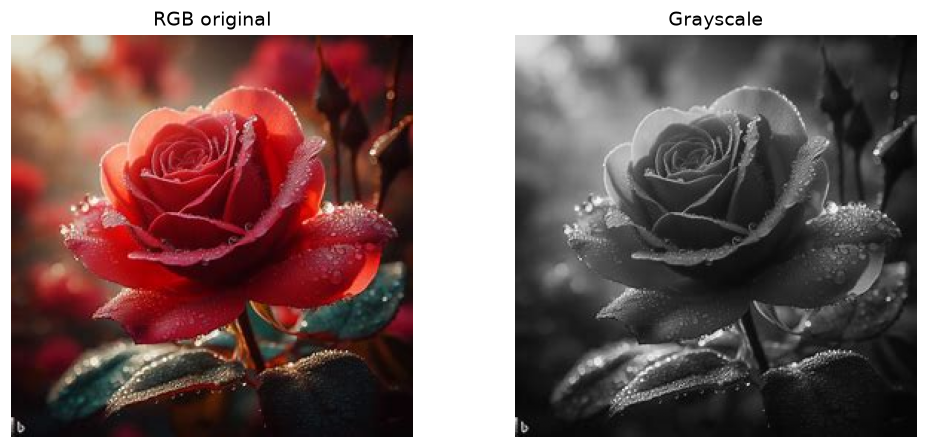

In [3]:
img_gray = img.convert('L')
gray_array = np.asarray(img_gray)
assert gray_array.ndim == 2

print('RGB shape:', img_array.shape)
print('Grayscale shape:', gray_array.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(img_array)
axes[0].set_title('RGB original')
axes[1].imshow(gray_array, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Grayscale')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '01_rgb_vs_grayscale.png', dpi=180, bbox_inches='tight')
plt.show()

**Cách nhận xét:** Hình dạng bông hoa vẫn nhìn thấy được, nhưng màu đỏ/xanh không còn phân biệt bằng màu. Nếu tác vụ cần thông tin màu, grayscale có thể làm mất dữ liệu quan trọng.

## 04. RGB Channel Visualization — Thí nghiệm 3

**Mục đích:** Tách ảnh thành ba kênh riêng để xem mỗi kênh đóng góp gì.

- `img.split()` tạo ba ảnh kênh đơn R, G, B.
- Hiển thị từng kênh bằng `Reds`, `Greens`, `Blues`.
- Cố định thang `0–255` để việc so sánh nhất quán.

**Lưu ý:** Màu hiển thị do *colormap* quyết định. Đừng suy luận giá trị pixel cao/thấp chỉ từ “đỏ nhạt/đỏ đậm” nếu chưa nhìn thang màu hoặc giá trị số.

*Nguồn đối chiếu: Chapter 4, trang PDF 11–12, Hình 4.5.*

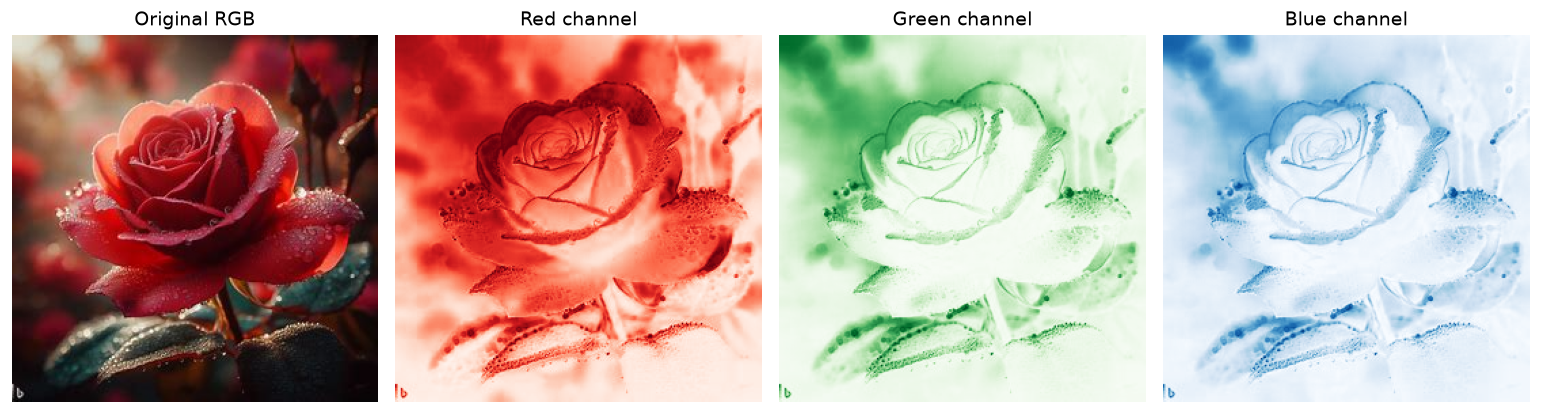

Kênh R: min=  0, max=255, trung bình=112.1
Kênh G: min=  0, max=255, trung bình=52.3
Kênh B: min=  0, max=244, trung bình=48.0


In [4]:
r_img, g_img, b_img = img.split()
r_array = np.asarray(r_img)
g_array = np.asarray(g_img)
b_array = np.asarray(b_img)
channels_data = [r_array, g_array, b_array]

# Kiểm tra ba kênh ghép lại đúng bằng ảnh ban đầu.
assert np.array_equal(np.stack(channels_data, axis=-1), img_array)

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.5))
axes[0].imshow(img_array)
axes[0].set_title('Original RGB')
for ax, arr, cmap, title in zip(
    axes[1:], channels_data,
    ['Reds', 'Greens', 'Blues'], ['Red channel', 'Green channel', 'Blue channel']
):
    ax.imshow(arr, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(title)
for ax in axes:
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '02_rgb_channels.png', dpi=180, bbox_inches='tight')
plt.show()

for name, arr in zip(['R', 'G', 'B'], channels_data):
    print(f'Kênh {name}: min={arr.min():3d}, max={arr.max():3d}, trung bình={arr.mean():.1f}')

**Cách nhận xét:** So sánh vị trí sáng/tối giữa các kênh để biết những vùng ảnh mang cường độ đỏ, xanh lá, xanh dương cao hoặc thấp. Bảng min/max/trung bình cho phép kiểm tra bằng số, không chỉ bằng mắt.

## 05. Image Histogram Analysis — Thí nghiệm 4 & 5

Histogram biểu diễn **số pixel ở mỗi mức giá trị**.

- Trục X: giá trị pixel từ `0` đến `255`.
- Trục Y: số pixel ứng với giá trị đó.
- Bên trái: mức giá trị thấp; bên phải: mức giá trị cao.

**Thí nghiệm 4:** Histogram ảnh **grayscale** để xem phân bố độ sáng.  
**Thí nghiệm 5 (mở rộng có chủ đích):** Ba histogram **R, G, B** để xem phân bố từng kênh màu.

> **Điểm cần sửa cách diễn giải trong ví dụ của sách:** `plt.hist(img_array.ravel(), bins=256)` gộp **cả ba kênh RGB** làm một phân bố. Nó **không phải** histogram độ sáng grayscale. Notebook này tách hai loại để tránh nhầm lẫn.

*Nguồn đối chiếu: Chapter 4, trang PDF 9–10, Hình 4.3 (biểu đồ pixel), và trang 11–12 (các kênh màu).*

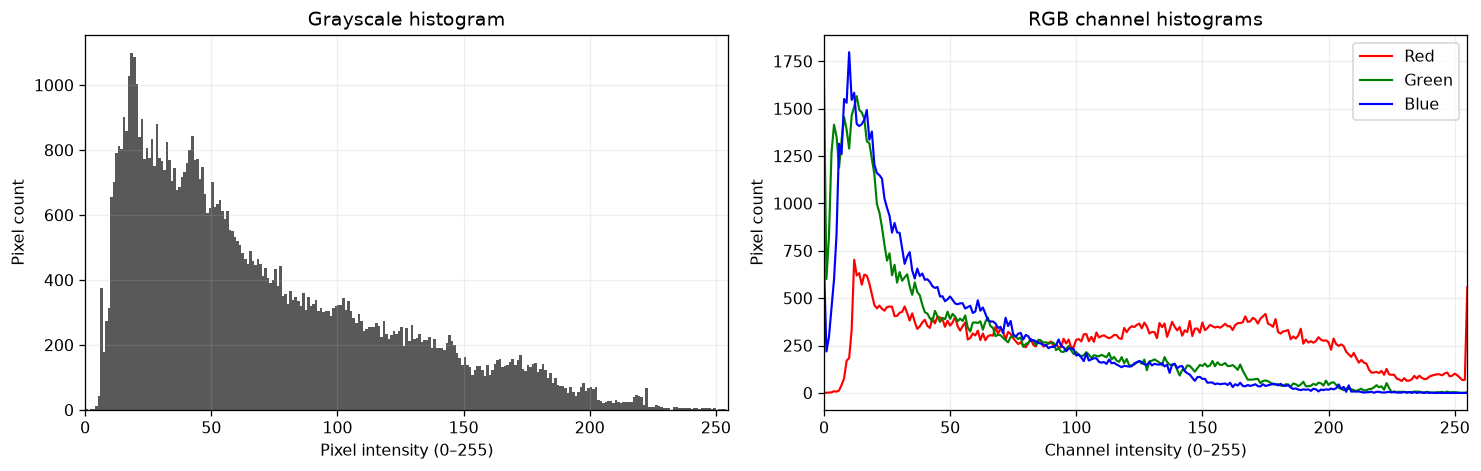

Grayscale: mean=69.7, median=55.0, std=50.1
Số pixel trong mỗi histogram một kênh: 72900


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Thí nghiệm 4: histogram mức xám.
axes[0].hist(gray_array.ravel(), bins=256, range=(0, 256), color='0.35')
axes[0].set_title('Grayscale histogram')
axes[0].set_xlabel('Pixel intensity (0–255)')
axes[0].set_ylabel('Pixel count')
axes[0].set_xlim(0, 255)
axes[0].grid(alpha=0.2)

# Thí nghiệm 5: các histogram màu, mỗi kênh có height × width pixel.
for name, channel, color in [
    ('Red', r_array, 'red'),
    ('Green', g_array, 'green'),
    ('Blue', b_array, 'blue')
]:
    histogram = np.bincount(channel.ravel(), minlength=256)
    axes[1].plot(np.arange(256), histogram, color=color, label=name, linewidth=1.35)
axes[1].set_title('RGB channel histograms')
axes[1].set_xlabel('Channel intensity (0–255)')
axes[1].set_ylabel('Pixel count')
axes[1].set_xlim(0, 255)
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / '03_histograms.png', dpi=180, bbox_inches='tight')
plt.show()

print(f'Grayscale: mean={gray_array.mean():.1f}, median={np.median(gray_array):.1f}, std={gray_array.std():.1f}')
print('Số pixel trong mỗi histogram một kênh:', height * width)

**Cách đọc kết quả:**

- Histogram grayscale cho biết ảnh có nhiều pixel sáng hay tối.
- Ba đường RGB cho biết cường độ màu phân bố khác nhau như thế nào.
- Giá trị trung bình là mô tả tổng quát; **không** đủ để xác định một ảnh “đẹp/xấu” hay kết luận mô hình sẽ hoạt động tốt.
- Histogram không mô tả **vị trí** của pixel. Hai ảnh có bố cục khác nhau vẫn có thể có histogram giống nhau.

## 06. EDA Insights & Conclusions

### Kết quả rút ra từ năm thí nghiệm

| Quan sát | Ý nghĩa |
|---|---|
| RGB có ba kênh, grayscale có một kênh | Chọn cách biểu diễn ảnh tùy nhu cầu bài toán |
| Có thể tách R, G, B và kiểm tra từng kênh | Phân tích màu thay vì chỉ nhìn ảnh bằng mắt |
| Histogram thể hiện phân bố pixel | Kiểm tra độ sáng và cường độ màu ở mức thống kê |
| Thông tin màu và độ sáng không giống nhau | Tránh đánh đồng histogram RGB với grayscale |

**Vai trò của EDA trước khi huấn luyện:** Giúp hiểu cấu trúc dữ liệu, kiểm tra các dấu hiệu cần xử lý và đưa ra lựa chọn tiền xử lý có cơ sở. EDA **không tự chứng minh** rằng một cách tiền xử lý sẽ làm mô hình tốt hơn; muốn biết điều đó cần thí nghiệm và đánh giá mô hình.

### Giới hạn & hướng mở rộng

- Notebook mới phân tích **một ảnh**; muốn phân tích bộ dữ liệu phải khảo sát nhiều ảnh và nhãn.
- Việc kiểm tra kích thước hàng loạt, ảnh lỗi, mất cân bằng lớp và tính hiệu quả của tiền xử lý nằm ngoài phạm vi năm thí nghiệm hiện tại.
- Segmentation/HOG thuộc phần Tiến; resize/normalization/augmentation thuộc phần Tú.

In [6]:
# In tóm tắt có số liệu thực tế, không cần viết tay trước khi chạy.
print('=== EDA SUMMARY ===')
print(f'Nguồn ảnh: {image_path.name}')
print(f'Ảnh RGB: {width} × {height}, {channels} kênh, dtype={img_array.dtype}')
print(f'Ảnh grayscale: {gray_array.shape}, mean intensity={gray_array.mean():.1f}/255')
print('Trung bình từng kênh RGB:',
      ', '.join(f'{label}={arr.mean():.1f}' for label, arr in zip(['R','G','B'], channels_data)))
print('Các hình xuất ra:')
for file in sorted(OUTPUT_DIR.glob('*.png')):
    print(' -', file.as_posix())

=== EDA SUMMARY ===
Nguồn ảnh: roseflower.jpeg
Ảnh RGB: 270 × 270, 3 kênh, dtype=uint8
Ảnh grayscale: (270, 270), mean intensity=69.7/255
Trung bình từng kênh RGB: R=112.1, G=52.3, B=48.0
Các hình xuất ra:
 - /home/thien408/Projects/2026-2027/PR_seminar_bakhi/outputs/thien/01_rgb_vs_grayscale.png
 - /home/thien408/Projects/2026-2027/PR_seminar_bakhi/outputs/thien/02_rgb_channels.png
 - /home/thien408/Projects/2026-2027/PR_seminar_bakhi/outputs/thien/03_histograms.png


### Gợi ý diễn đạt trong seminar (khoảng 7 phút)

1. **~1 phút:** EDA là gì, lý do phân tích ảnh trước khi xây dựng mô hình.
2. **~1 phút:** Ảnh RGB là một mảng số có ba kênh.
3. **~1 phút:** Chuyển grayscale và đánh đổi thông tin màu.
4. **~2 phút:** Tách R, G, B và giải thích các kênh.
5. **~1,5 phút:** Histogram grayscale so với RGB, nhận xét về phân bố.
6. **~0,5 phút:** Chốt vai trò của EDA và giới hạn khi chỉ có một ảnh.

### Tài liệu tham khảo

- Vijaya Kumar Suda (2024). *Data Labeling in Machine Learning with Python*, Chapter 4: *Exploring Image Data* (trang PDF 2–13).
- [Code Chapter 4 — PacktPublishing](https://github.com/PacktPublishing/Data-Labeling-in-Machine-Learning-with-Python/tree/main/code/Ch04).
- [Ảnh gốc trong kho sách](https://github.com/PacktPublishing/Data-Labeling-in-Machine-Learning-with-Python/blob/main/images/Ch4/roseflower.jpeg). 

**Phân biệt nguồn:** Code minh họa RGB, grayscale, split channels và histogram cơ bản được **tái lập, sắp xếp và bổ sung giải thích** từ Chapter 4. Histogram tách riêng từng kênh RGB, phần thống kê và xuất ảnh là **mở rộng phục vụ seminar**.